# Day 29 | Read Word, Excel, and PowerPoint Files

**KGP Talkie**

Keep document text, table cells, and slide labels clear.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

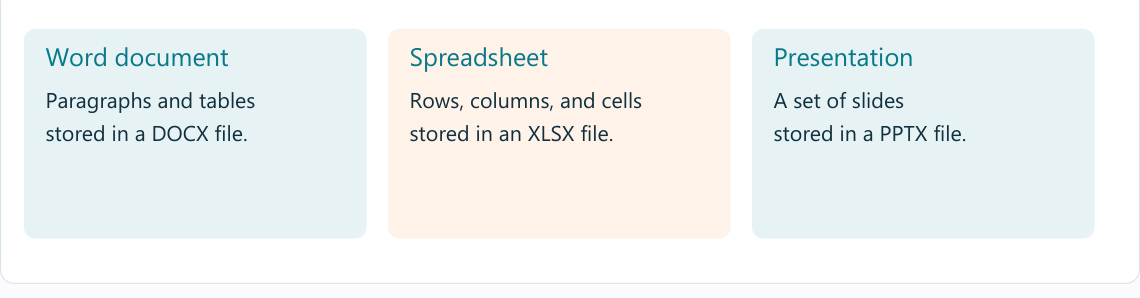

Three matching readers preserve the file types. These are small local files created for class.

In [4]:
from docx import Document
from openpyxl import load_workbook
from pptx import Presentation

In [5]:
word = Document(ASSETS / "job.docx")

Skip empty paragraphs; the remaining text stays in document order.

In [6]:
paragraphs = [p.text for p in word.paragraphs if p.text.strip()]
print(paragraphs)

['Teaching assistant role', 'Explain Python clearly. Required skills: Python and Pandas.']


In [7]:
sheet = load_workbook(ASSETS / "sales.xlsx", data_only=True).active

values_only returns cell values. data_only reads cached formula results if formulas exist; our sample uses numbers.

In [8]:
rows = list(sheet.iter_rows(values_only=True))
print(rows)

[('Workshop', 'Sales'), ('Python', 120), ('Pandas', 80)]


Skip the heading row. Python calculates the exact number before any model summary.

In [9]:
total = sum(row[1] for row in rows[1:])
print("Exact total:", total)

Exact total: 200


In [10]:
slides = Presentation(ASSETS / "lesson.pptx").slides

Each slide keeps its number. Text boxes are read; pictures need a separate image step.

In [11]:
for i, slide in enumerate(slides):
    texts = [shape.text for shape in slide.shapes if shape.has_text_frame]
    print("Slide", i + 1, texts)

Slide 1 ['Python', 'Variables store values.']
Slide 2 ['Pandas', 'DataFrames have rows and columns.']


ChatOllama sends chat requests to the local Ollama server.

In [12]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [13]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [14]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [15]:
print(llm.invoke(f"Write one sentence about these workshop sales. Use the given total {total}, do not recalculate. Rows: {rows}").content)

The total sales for the workshops were $200, with Python and Pandas accounting for $200 of that amount.


Try a fresh slide fact without changing the file readers.

In [16]:
print(llm.invoke("Draft one short speaker note: A DataFrame stores rows and columns.").content)

Here's a possible speaker note:

"Ladies and gentlemen, when working with data in Python, it's essential to understand the fundamental structure of a DataFrame. A DataFrame is essentially a table that stores rows and columns, similar to an Excel spreadsheet or a relational database. Each row represents a single observation or record, while each column represents a variable or attribute associated with that observation."


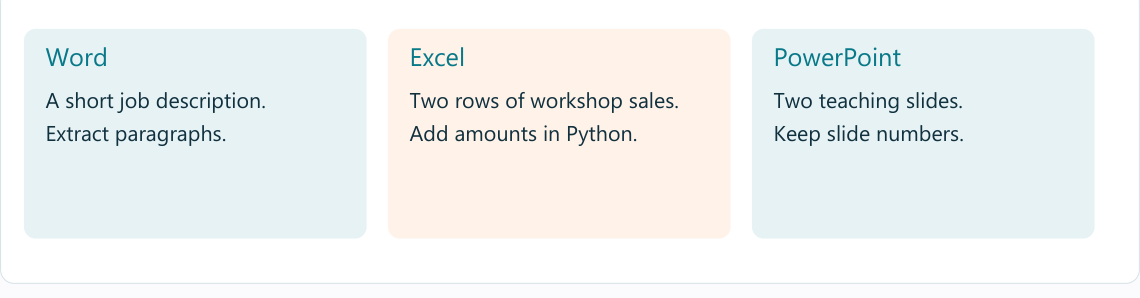

## Try a fresh input

Try a new row or paragraph. Check whether the extracted structure remains clear.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-document-loaders).